---
title: 'Solutions: From Continuous Flows to Score Matching'
author: Mark Fuge
format:
    html:
        code-fold: true
        code-summary: "Show Solution Code"
---

These are worked solutions to the exercises at the end of the chapter *From Continuous Flows to Score Matching*.

In [1]:
import sys
from math import erf

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
import torch.optim as optim

sys.path.insert(0, '../part2/gen_models')
import gen_models_utilities  # noqa: F401  (sets the plotting style and the seeds, as in the chapter)

plt.style.use('seaborn-v0_8-muted')
sns.set_context('talk')
device = "cpu"
EX_SEED = 42

In [2]:
# The chapter's score network and Langevin sampler
class ScoreNet2D(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden),
            nn.Softplus(),
            nn.Linear(hidden, hidden),
            nn.Softplus(),
            nn.Linear(hidden, 2)
        )

    def forward(self, x):
        return self.net(x)


def langevin_sampler_2d(score_model, n_samples=500, n_steps=200, alpha=0.01, initial_noise_scale=5.0, track_trajectories=False, tracked_points=None):
    """Generate samples using Langevin Dynamics, with optional trajectory tracking."""
    if track_trajectories and tracked_points is not None:
        x = tracked_points.to(device)
        n_samples = tracked_points.shape[0]
    else:
        x = torch.randn(n_samples, 2, device=device) * initial_noise_scale

    trajectory = [x.cpu().detach().numpy()]

    score_model.eval()
    with torch.no_grad():
        for _ in range(n_steps):
            score = score_model(x)
            noise = torch.randn_like(x) * np.sqrt(2 * alpha)
            x = x + alpha * score + noise
            trajectory.append(x.cpu().detach().numpy())

    return x, np.array(trajectory)

### Exercise 1: Which noise level made this field?

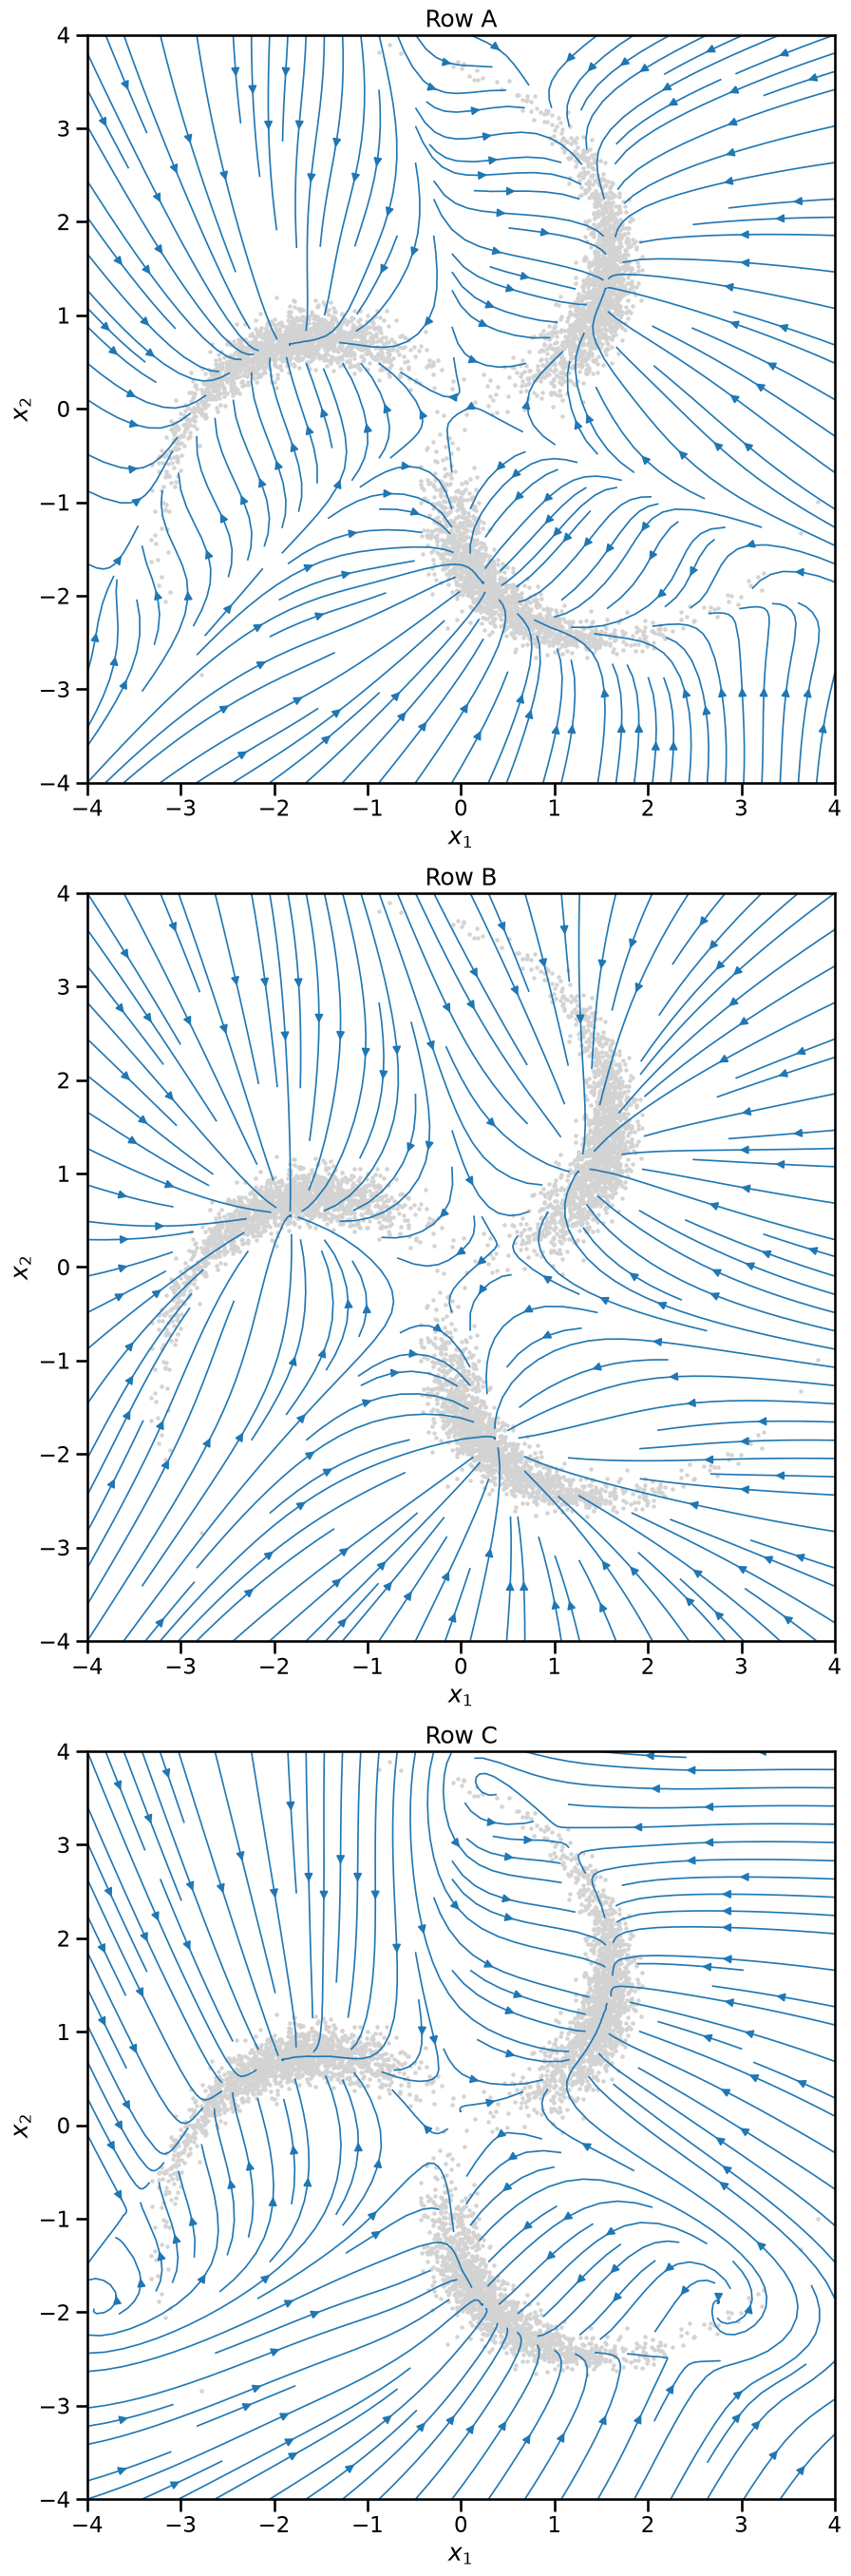

In [3]:
# Figure for Exercise 1: denoising score matching on a pinwheel at three noise levels (rows shuffled)
EX_SEED = 42
EX1_SIGMAS = {'A': 0.3, 'B': 1.0, 'C': 0.1}  # row letter -> noise level used in training
EX1_STEPS = 3000  # gradient steps per network (the chapter's ring run took 400 epochs of 20 batches)


def make_pinwheel(n, rng, n_arms=3, radial_std=0.3, tangential_std=0.08, rate=0.25):
    # Pinwheel data: Gaussian blobs stretched along the radius and bent into curved arms
    arm_angles = np.linspace(0, 2 * np.pi, n_arms, endpoint=False)
    feats = rng.standard_normal((n, 2)) * [radial_std, tangential_std]
    feats[:, 0] += 1.0
    angle = arm_angles[rng.integers(n_arms, size=n)] + rate * np.exp(feats[:, 0])
    c, s = np.cos(angle), np.sin(angle)
    x = np.stack([c * feats[:, 0] - s * feats[:, 1], s * feats[:, 0] + c * feats[:, 1]], axis=1)
    return (2.0 * x).astype(np.float32)


def train_dsm(X_train, sigma_train, steps=EX1_STEPS, batch_size=256, lr=1e-3, seed=EX_SEED):
    # The chapter's DSM loss and optimizer, on random mini-batches of X_train
    torch.manual_seed(seed)
    net = ScoreNet2D().to(device)
    opt = optim.AdamW(net.parameters(), lr=lr)
    for step in range(steps):
        x = X_train[torch.randint(0, len(X_train), (batch_size,))]
        noise = torch.randn_like(x) * sigma_train
        loss = ((net(x + noise) - (-noise / sigma_train ** 2)) ** 2).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
    net.eval()
    return net


X_pinwheel = torch.from_numpy(make_pinwheel(5000, np.random.default_rng(EX_SEED))).to(device)
pinwheel_nets = {letter: train_dsm(X_pinwheel, s) for letter, s in EX1_SIGMAS.items()}

pin_np = X_pinwheel.cpu().numpy()
g_fine = np.linspace(-4, 4, 160)
xx_f, yy_f = np.meshgrid(g_fine, g_fine)
grid_f = torch.tensor(np.stack([xx_f.ravel(), yy_f.ravel()], 1), dtype=torch.float32, device=device)

fig, axes = plt.subplots(3, 1, figsize=(10, 27), layout='constrained')
for ax, (letter, net) in zip(axes, pinwheel_nets.items()):
    with torch.no_grad():
        S_f = net(grid_f).cpu().numpy()
    ax.scatter(pin_np[:, 0], pin_np[:, 1], s=3, color='lightgray', zorder=0)
    ax.streamplot(xx_f, yy_f, S_f[:, 0].reshape(xx_f.shape), S_f[:, 1].reshape(xx_f.shape),
                  color='tab:blue', density=1.4, linewidth=1.2, arrowsize=1.3)
    ax.set_title(f'Row {letter}')
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect('equal')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
plt.show()

row sigma  median |s| at data  max |s| on grid  grid within 3 sigma of data
  A   0.3                1.55             29.5                         0.61
  B   1.0                0.30              3.7                         1.00
  C   0.1                3.16            102.6                         0.27

row sigma   cos with blurred score, near / far   length / blurred length, near / far
  A   0.3                          0.98 / 0.98                           0.88 / 0.88
  B   1.0                          1.00 / 1.00                           1.00 / 0.97
  C   0.1                          0.90 / 0.83                           0.61 / 0.29

Fresh pinwheel points: median distance to the nearest training point 0.014
Row A (sigma 0.3): median distance to the data 0.041, farther than 0.5 from the data 0.07, outside [-4, 4]^2 0.027
Row B (sigma 1.0): median distance to the data 0.505, farther than 0.5 from the data 0.50, outside [-4, 4]^2 0.136
Row C (sigma 0.1): median distance to the data 0.

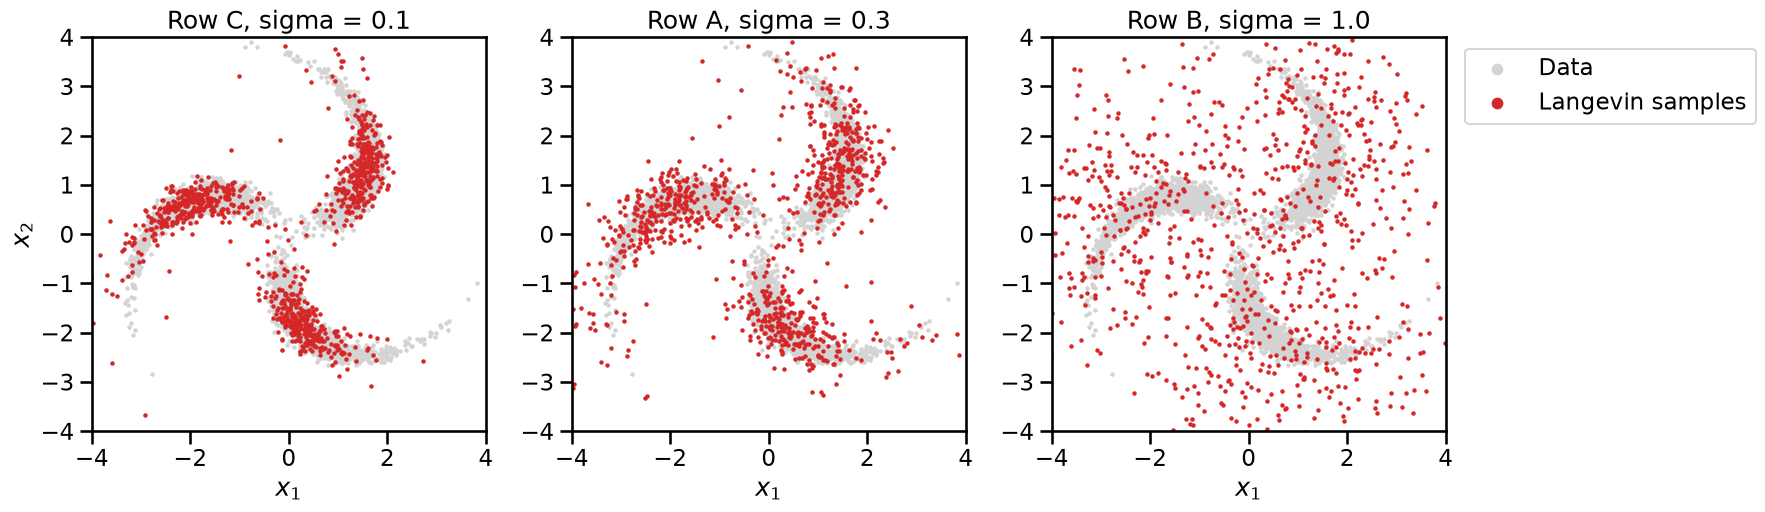

In [4]:
# How strong each field is, and how much of the plotted window its training data covered
g_coarse = np.linspace(-4, 4, 25)
xx_c, yy_c = np.meshgrid(g_coarse, g_coarse)
grid_c = torch.tensor(np.stack([xx_c.ravel(), yy_c.ravel()], 1), dtype=torch.float32, device=device)
dist_grid = torch.cdist(grid_c, X_pinwheel).min(dim=1).values.cpu().numpy()


def blurred_data_score(y, sigma):
    # Exact score of the training points blurred with N(0, sigma^2 I): a weighted pull toward all of them
    weights = torch.softmax(-torch.cdist(y, X_pinwheel) ** 2 / (2 * sigma ** 2), dim=1)
    return (weights @ X_pinwheel - y) / sigma ** 2


print(f"{'row':>3} {'sigma':>5} {'median |s| at data':>19} {'max |s| on grid':>16} {'grid within 3 sigma of data':>28}")
for letter, net in pinwheel_nets.items():
    s_train = EX1_SIGMAS[letter]
    with torch.no_grad():
        s_data = net(X_pinwheel).norm(dim=1).cpu().numpy()
        s_grid = net(grid_c).norm(dim=1).cpu().numpy()
    print(f"{letter:>3} {s_train:5.1f} {np.median(s_data):19.2f} {s_grid.max():16.1f} {np.mean(dist_grid < 3 * s_train):28.2f}")

# Compare each field with the exact score of the training data blurred with N(0, sigma^2 I),
# separately near the data (within 3 sigma) and far from it
print(f"\n{'row':>3} {'sigma':>5} {'cos with blurred score, near / far':>36} {'length / blurred length, near / far':>37}")
for letter, net in pinwheel_nets.items():
    s_train = EX1_SIGMAS[letter]
    with torch.no_grad():
        s_net = net(grid_c)
    s_blur = blurred_data_score(grid_c, s_train)
    near = torch.from_numpy(dist_grid < 3 * s_train)
    cos_blur = torch.nn.functional.cosine_similarity(s_net, s_blur, dim=1)
    ratio = s_net.norm(dim=1) / s_blur.norm(dim=1)
    near_text = f"{cos_blur[near].median():.2f} / " + (f"{cos_blur[~near].median():.2f}" if (~near).any() else "-")
    ratio_text = f"{ratio[near].median():.2f} / " + (f"{ratio[~near].median():.2f}" if (~near).any() else "-")
    print(f"{letter:>3} {s_train:5.1f} {near_text:>36} {ratio_text:>37}")

# The chapter's sampler (alpha = 0.01, 200 steps, start from N(0, 5^2 I)) with each network
X_fresh = torch.from_numpy(make_pinwheel(1000, np.random.default_rng(EX_SEED + 1))).to(device)
d_fresh = torch.cdist(X_fresh, X_pinwheel).min(dim=1).values.cpu().numpy()
print(f"\nFresh pinwheel points: median distance to the nearest training point {np.median(d_fresh):.3f}")
pinwheel_samples = {}
for letter, net in pinwheel_nets.items():
    torch.manual_seed(EX_SEED)
    x, _ = langevin_sampler_2d(net, n_samples=1000, alpha=0.01)
    pinwheel_samples[letter] = x.cpu().numpy()
    d = torch.cdist(x, X_pinwheel).min(dim=1).values.cpu().numpy()
    print(f"Row {letter} (sigma {EX1_SIGMAS[letter]}): median distance to the data {np.median(d):.3f}, "
          f"farther than 0.5 from the data {np.mean(d > 0.5):.2f}, outside [-4, 4]^2 {np.mean(np.abs(pinwheel_samples[letter]).max(axis=1) > 4):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6.3))
for ax, (letter, x) in zip(axes, sorted(pinwheel_samples.items(), key=lambda kv: EX1_SIGMAS[kv[0]])):
    ax.scatter(pin_np[:, 0], pin_np[:, 1], s=3, color='lightgray', label='Data')
    ax.scatter(x[:, 0], x[:, 1], s=3, color='tab:red', label='Langevin samples')
    ax.set_title(f'Row {letter}, sigma = {EX1_SIGMAS[letter]}')
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect('equal')
    ax.set_xlabel('$x_1$')
axes[0].set_ylabel('$x_2$')
axes[-1].legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), markerscale=4)
plt.tight_layout()
plt.show()

**(a)** Row C is $\sigma = 0.1$, row A is $\sigma = 0.3$ and row B is $\sigma = 1.0$.

The loss regresses $s_\theta(x + \epsilon)$ onto $-\epsilon/\sigma^2$. The best network for this loss outputs the score of the noisy distribution $p_\sigma$. That is the data blurred with $\mathcal{N}(0, \sigma^2 I)$. Two features of the rows follow from this.

- Shape near the data. In rows C and A, the streamlines cross onto each arm and end all along it. The arms are about 0.16 wide (one standard deviation across). Blurring with $\sigma = 0.3$ widens them to about $\sqrt{0.16^2 + 0.3^2} = 0.34$. That is still much less than the gaps between the arms, so $p_\sigma$ is still a set of curved ridges. In row B, the streamlines run into three round sinks. Noise with standard deviation 1.0 is as large as the gaps between the arms. So $p_\sigma$ has three round blobs instead of curved arms.
- Far from the data. In row C, the streamlines curl into swirls away from the arms, near $(2.8, -1.8)$ and $(-3.6, -1.8)$. The network only saw inputs $x + \epsilon$ within about $3\sigma = 0.3$ of the arms. That covers 27% of the window. Everywhere else, its output is extrapolation. There it is a poor copy of the exact score of the blurred training points. Its median length is 0.29 times the exact one, and the median cosine between the two directions is 0.83. In row A, the inputs reach about $3\sigma = 0.9$ from the arms and cover 61% of the window. The field agrees with the exact score of the blurred training points everywhere in the window (median cosine 0.98 both near the data and far from it, median length ratio 0.88). Its streamlines come in smoothly from the edges, without swirls. In row B, the inputs cover the whole window. The field matches the exact score almost perfectly (median cosine 1.00, median length ratio 1.00).

So in the figure, row A differs from row C by its smooth far field without swirls. It differs from row B by streamlines that end along the arms instead of in three sinks.

**(b)** The figure already shows what each network will produce. Langevin dynamics samples the distribution according to the score it uses, which here is $p_\sigma$, not the pinwheel itself. The streamlines of rows C and A end on the arms, so their samples will lie on the arms. For row A they will be a little thicker. The streamlines of row B end in three round sinks, so its samples will form three wide blobs. The runs in the code above confirm this.

- With $\sigma = 0.1$, the median distance from a sample to the nearest data point is 0.016. That is about the same as for fresh pinwheel points (0.014). Only 2% of the samples lie farther than 0.5 from the data.
- With $\sigma = 0.3$, the median distance is 0.041, and 7% of the samples lie farther than 0.5 from the data.
- With $\sigma = 1.0$, the median distance is 0.505. Half the samples lie farther than 0.5 from the data, and 14% lie outside the plotted window. These are correct samples of the pinwheel blurred with $\mathcal{N}(0, I)$. But that is not the distribution you wanted.

I would use row C ($\sigma = 0.1$) for the sharpest arms, or row A ($\sigma = 0.3$) as the safer choice. Each choice has a cost.

- $\sigma = 0.1$ learns the score only near the data. The sampler starts its points from $\mathcal{N}(0, 5^2 I)$, mostly far from the arms. There the field is extrapolated (the swirls in row C). In this run it still pointed inward well enough, but nothing in the training guarantees this. The field is also steep, so it needs a small step size. Exercises 2 and 4 show what happens otherwise.
- $\sigma = 0.3$ gives a field that follows the blurred data over the whole window. The price is arms about twice as wide as the real ones (0.34 instead of 0.16).
- $\sigma = 1.0$ gives a smooth field that is reliable everywhere and tolerates large steps. But the samples have lost the arms.

No single $\sigma$ gives a field that is both accurate near the data and reliable far from it. The section *The Final Bridge to Diffusion Models* raises this problem. Its answer is to start with a large $\sigma$ and lower it during sampling.

**(c)** The same noisy point $y$ can come from many data points, namely every $x$ within a few $\sigma$ of $y$. So for one input $y$, the loss sees many different targets, $(x - y)/\sigma^2$ for each such $x$. A squared error is smallest when the network outputs the average of its targets. Each data point $x_i$ enters that average with the probability that it produced $y$. That probability is proportional to $\exp(-\|y - x_i\|^2 / (2\sigma^2))$. The trained field is therefore

$$
s_\sigma(y) = \frac{1}{\sigma^2} \left( \sum_i w_i(y)\, x_i - y \right), \qquad w_i(y) = \frac{\exp\left(-\|y - x_i\|^2 / (2\sigma^2)\right)}{\sum_j \exp\left(-\|y - x_j\|^2 / (2\sigma^2)\right)}.
$$

It points from $y$ to a weighted average of the data points near $y$. This is the score of the data blurred with $\mathcal{N}(0, \sigma^2 I)$. With $\sigma = 1.0$, the weights reach over a whole arm and into its neighbors. The weighted average then sits in the thick part of an arm, or between arms, and not on any single data point. So the streamlines of row B run into three round sinks. The code above compares the network with this formula on a grid. In row B, the median cosine between the two directions is 1.00, and the median ratio of their lengths is 1.00. Rows A and C follow the same rule. But with a small $\sigma$, the weights only reach the part of one arm closest to $y$. So the average lies on the arm, right next to $y$.

### Exercise 2: Which sampler made these samples?

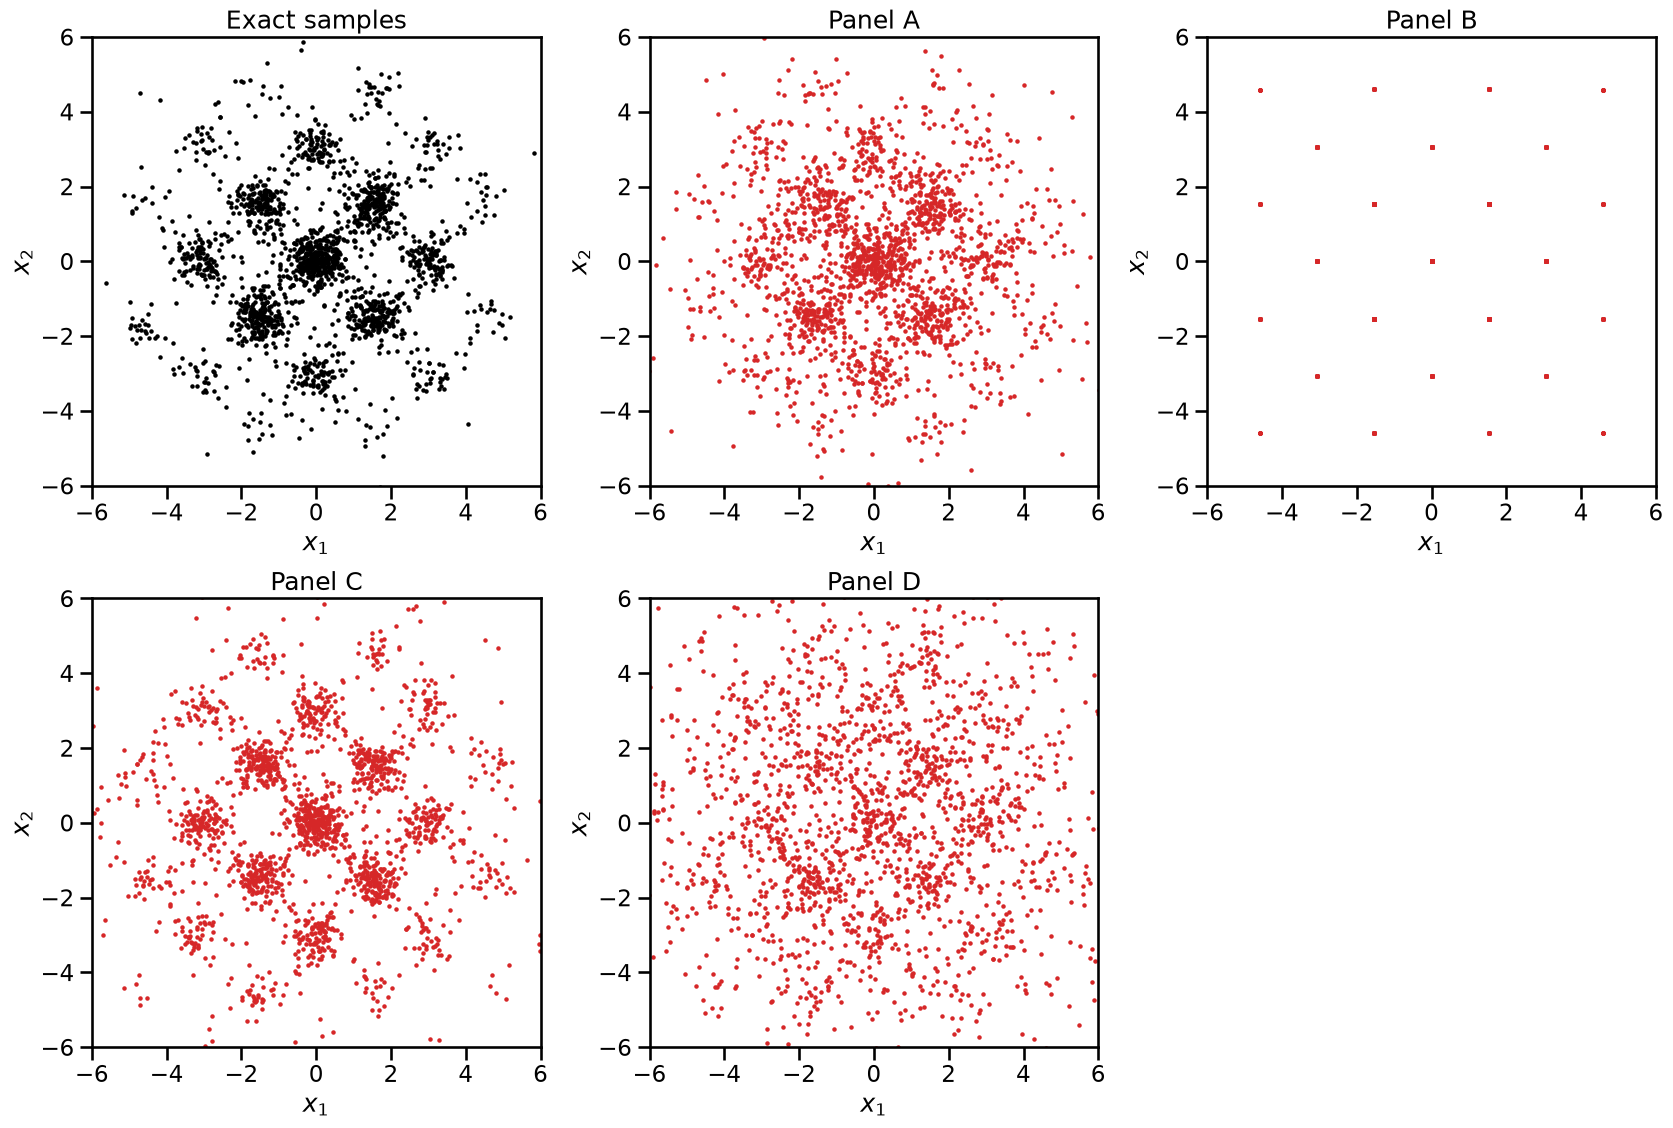

In [5]:
# Figure for Exercise 2: four samplers on the egg-carton density with its exact score (panels shuffled)
EX_SEED = 42
EGG_BETA, EGG_K, EGG_STD = 2.5, 2.0, 2.0
EX2_N, EX2_STEPS = 2000, 500


def egg_log_density(x):
    # Unnormalized log density: Gaussian envelope (std 2) plus a grid of bumps
    return -0.5 * (x ** 2).sum(-1) / EGG_STD ** 2 + EGG_BETA * torch.cos(EGG_K * x[:, 0]) * torch.cos(EGG_K * x[:, 1])


def egg_score(x):
    # Exact score by automatic differentiation of the log density
    x = x.detach().requires_grad_(True)
    (grad,) = torch.autograd.grad(egg_log_density(x).sum(), x)
    return grad


def egg_exact_samples(n, seed=EX_SEED):
    # Rejection sampling from the Gaussian envelope: accept with probability exp(beta cos cos - beta)
    gen = torch.Generator().manual_seed(seed)
    out, total = [], 0
    while total < n:
        y = EGG_STD * torch.randn(20 * n, 2, generator=gen)
        accept = torch.exp(EGG_BETA * torch.cos(EGG_K * y[:, 0]) * torch.cos(EGG_K * y[:, 1]) - EGG_BETA)
        keep = y[torch.rand(len(y), generator=gen) < accept]
        out.append(keep)
        total += len(keep)
    return torch.cat(out)[:n].numpy()


def run_egg_sampler(alpha, deterministic=False, n=EX2_N, steps=EX2_STEPS, seed=EX_SEED):
    # x <- x + alpha * score(x) + sqrt(2 * alpha) * z (no noise term if deterministic), starting from N(0, 3^2 I)
    torch.manual_seed(seed)
    x = 3.0 * torch.randn(n, 2)
    for _ in range(steps):
        x = x + alpha * egg_score(x)
        if not deterministic:
            x = x + np.sqrt(2 * alpha) * torch.randn_like(x)
    return x.numpy()


egg_exact = egg_exact_samples(EX2_N)
EX2_SETTINGS = {  # panel letter -> sampler (the exercise's table maps settings to panels)
    'A': ('Langevin, alpha 0.1', dict(alpha=0.1)),
    'B': ('Ascent, alpha 0.01', dict(alpha=0.01, deterministic=True)),
    'C': ('Langevin, alpha 0.01', dict(alpha=0.01)),
    'D': ('Langevin, alpha 0.0001', dict(alpha=1e-4)),
}
egg_panels = {letter: run_egg_sampler(**kw) for letter, (name, kw) in EX2_SETTINGS.items()}

fig, axes = plt.subplots(2, 3, figsize=(17, 11.5))
axes[-1, -1].axis('off')  # five panels on a 2 x 3 grid
panels = [('Exact samples', egg_exact)] + [(f'Panel {letter}', x) for letter, x in egg_panels.items()]
for ax, (title, x) in zip(axes.ravel(), panels):
    ax.scatter(x[:, 0], x[:, 1], s=3, color='k' if title == 'Exact samples' else 'tab:red')
    ax.set_title(title)
    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)
    ax.set_aspect('equal')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
plt.tight_layout()
plt.show()

In [6]:
# Three numbers per panel: overall spread, how high up the bumps the points sit, and how many sit at a bump top
def bump_offsets(x):
    # Offset of each point from the nearest bump top; the tops form two square grids with spacing pi,
    # one through the origin and one shifted by (pi/2, pi/2)
    off1 = x - np.pi * np.round(x / np.pi)
    y = x - np.pi / 2
    off2 = y - np.pi * np.round(y / np.pi)
    closer = np.linalg.norm(off1, axis=1) < np.linalg.norm(off2, axis=1)
    return np.where(closer[:, None], off1, off2)


def panel_stats(x):
    off = np.linalg.norm(bump_offsets(x), axis=1)
    cc = np.cos(EGG_K * x[:, 0]) * np.cos(EGG_K * x[:, 1])
    return np.sqrt((x ** 2).sum(axis=1).mean()), cc.mean(), np.mean(off < 0.3)


print(f"{'':48s} {'rms radius':>10} {'mean cos(2x1)cos(2x2)':>22} {'within 0.3 of a bump top':>25}")
print(f"{'Exact samples':48s} " + "{:10.2f} {:22.2f} {:25.2f}".format(*panel_stats(egg_exact)))
for letter, (name, kw) in EX2_SETTINGS.items():
    print(f"{'Panel ' + letter + ': ' + name:48s} " + "{:10.2f} {:22.2f} {:25.2f}".format(*panel_stats(egg_panels[letter])))
print(f"\nCurvature of log p at a bump top: beta k^2 = {EGG_BETA * EGG_K ** 2:.0f} (plus {1 / EGG_STD ** 2:.2f} from the envelope)")
print(f"Points farther than 4 from the origin: exact {np.mean(np.linalg.norm(egg_exact, axis=1) > 4):.2f}, "
      f"panel C {np.mean(np.linalg.norm(egg_panels['C'], axis=1) > 4):.2f}")

                                                 rms radius  mean cos(2x1)cos(2x2)  within 0.3 of a bump top
Exact samples                                          2.78                   0.53                      0.28
Panel A: Langevin, alpha 0.1                           2.97                   0.31                      0.16
Panel B: Ascent, alpha 0.01                            4.12                   0.98                      1.00
Panel C: Langevin, alpha 0.01                          3.32                   0.53                      0.27
Panel D: Langevin, alpha 0.0001                        4.19                   0.21                      0.13

Curvature of log p at a bump top: beta k^2 = 10 (plus 0.25 from the envelope)
Points farther than 4 from the origin: exact 0.15, panel C 0.25


Setting 1 made panel B, setting 2 made panel D, setting 3 made panel C, and setting 4 made panel A.

| Setting | Panel | What gives it away |
|---|---|---|
| 1, ascent, $\alpha = 0.01$ | B | Every point sits exactly on a bump top (100% within 0.3 of a top) |
| 2, Langevin, $\alpha = 0.0001$ | D | A wide cloud with hardly any bumps, like the start |
| 3, Langevin, $\alpha = 0.01$ | C | Bumps of the right shape |
| 4, Langevin, $\alpha = 0.1$ | A | Blurred bumps, many points between them |

- Panel B. Without noise, the update climbs to the nearest local maximum of $\log p$ and stops. The samples collapse onto the bump tops. The mean of $\cos(2x_1)\cos(2x_2)$ is 0.98, against 0.53 for exact samples. Each point also stays in the bump where it started. So the outer bumps keep as many points as the start put there (root-mean-square radius 4.12, against 2.78 for exact samples).
- Panel D. 500 steps of $\alpha = 0.0001$ add up to a total time of $500\alpha = 0.05$. In that time the noise moves each point by only about $\sqrt{2 \cdot 0.05} = 0.32$. That is roughly the width of one bump. So the cloud still looks like the start. Its root-mean-square radius is 4.19, against $3\sqrt{2} = 4.24$ for $\mathcal{N}(0, 3^2 I)$. Only 13% of the points are within 0.3 of a bump top (28% for exact samples). The sampler has not mixed.
- Panel C. The bumps match the exact samples. The mean of $\cos(2x_1)\cos(2x_2)$ is 0.53 in both. Within 0.3 of a top, the panel has 27% of its points and the exact samples have 28%. The panel still has too many points in the outer bumps. In the panel, 25% of the points lie farther than 4 from the origin, against 15% for exact samples. The start was wider than the target, and a point leaves its bump only rarely. This is the same effect as in Exercise 3.
- Panel A. The step is too large for the bumps, and this blurs them. Only 16% of the points are within 0.3 of a top, and the mean of $\cos(2x_1)\cos(2x_2)$ drops to 0.31. Near a bump top, the drift $\alpha s(x)$ with $\alpha = 0.1$ is just large enough to carry a point from anywhere on the bump to its top in one step. The drift lands on the top, and the noise $\sqrt{2\alpha}\, z_k$, with standard deviation 0.45, kicks the point out again. It kicks it farther than the bump's own width of 0.32. The chain never settles into the bump's shape, so the points spread out between the bumps. With $\alpha = 0.01$, the drift moves a point only a tenth of the way to the top per step, and the noise has standard deviation 0.14. Many small steps then average out and trace the bump correctly. So a larger step does not reach the same distribution faster. It changes the distribution the chain settles at.

The formula of Exercise 5 puts a number on this. Near a top, $\log p$ is close to a parabola with curvature $2.5 \cdot 2^2 = 10$. That is a local Gaussian with variance $s^2 = 0.1$. The sampled variance is $s^2 / (1 - \alpha/(2s^2))$. For $\alpha = 0.01$ it is 1.05 times the true one, which you cannot see. For $\alpha = 0.1$ it is 2 times the true one, which makes the bumps $\sqrt{2}$ times too wide.

### Exercise 3: Langevin step by step in 1D

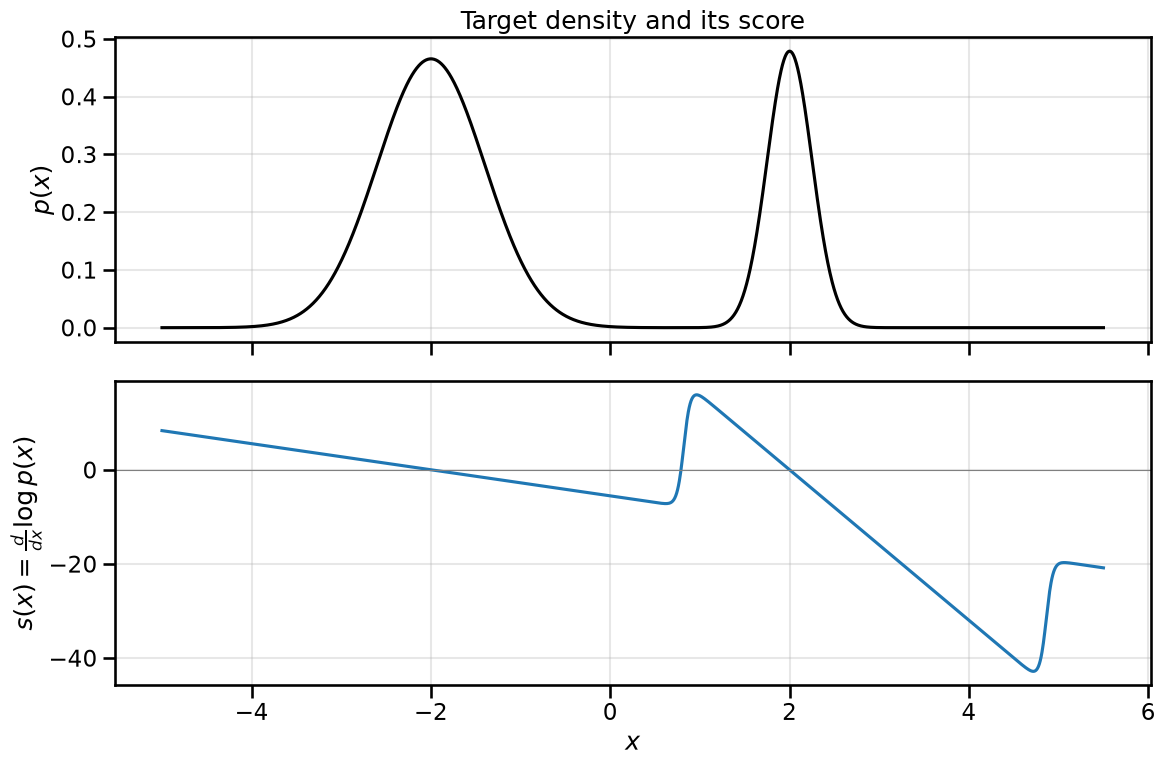

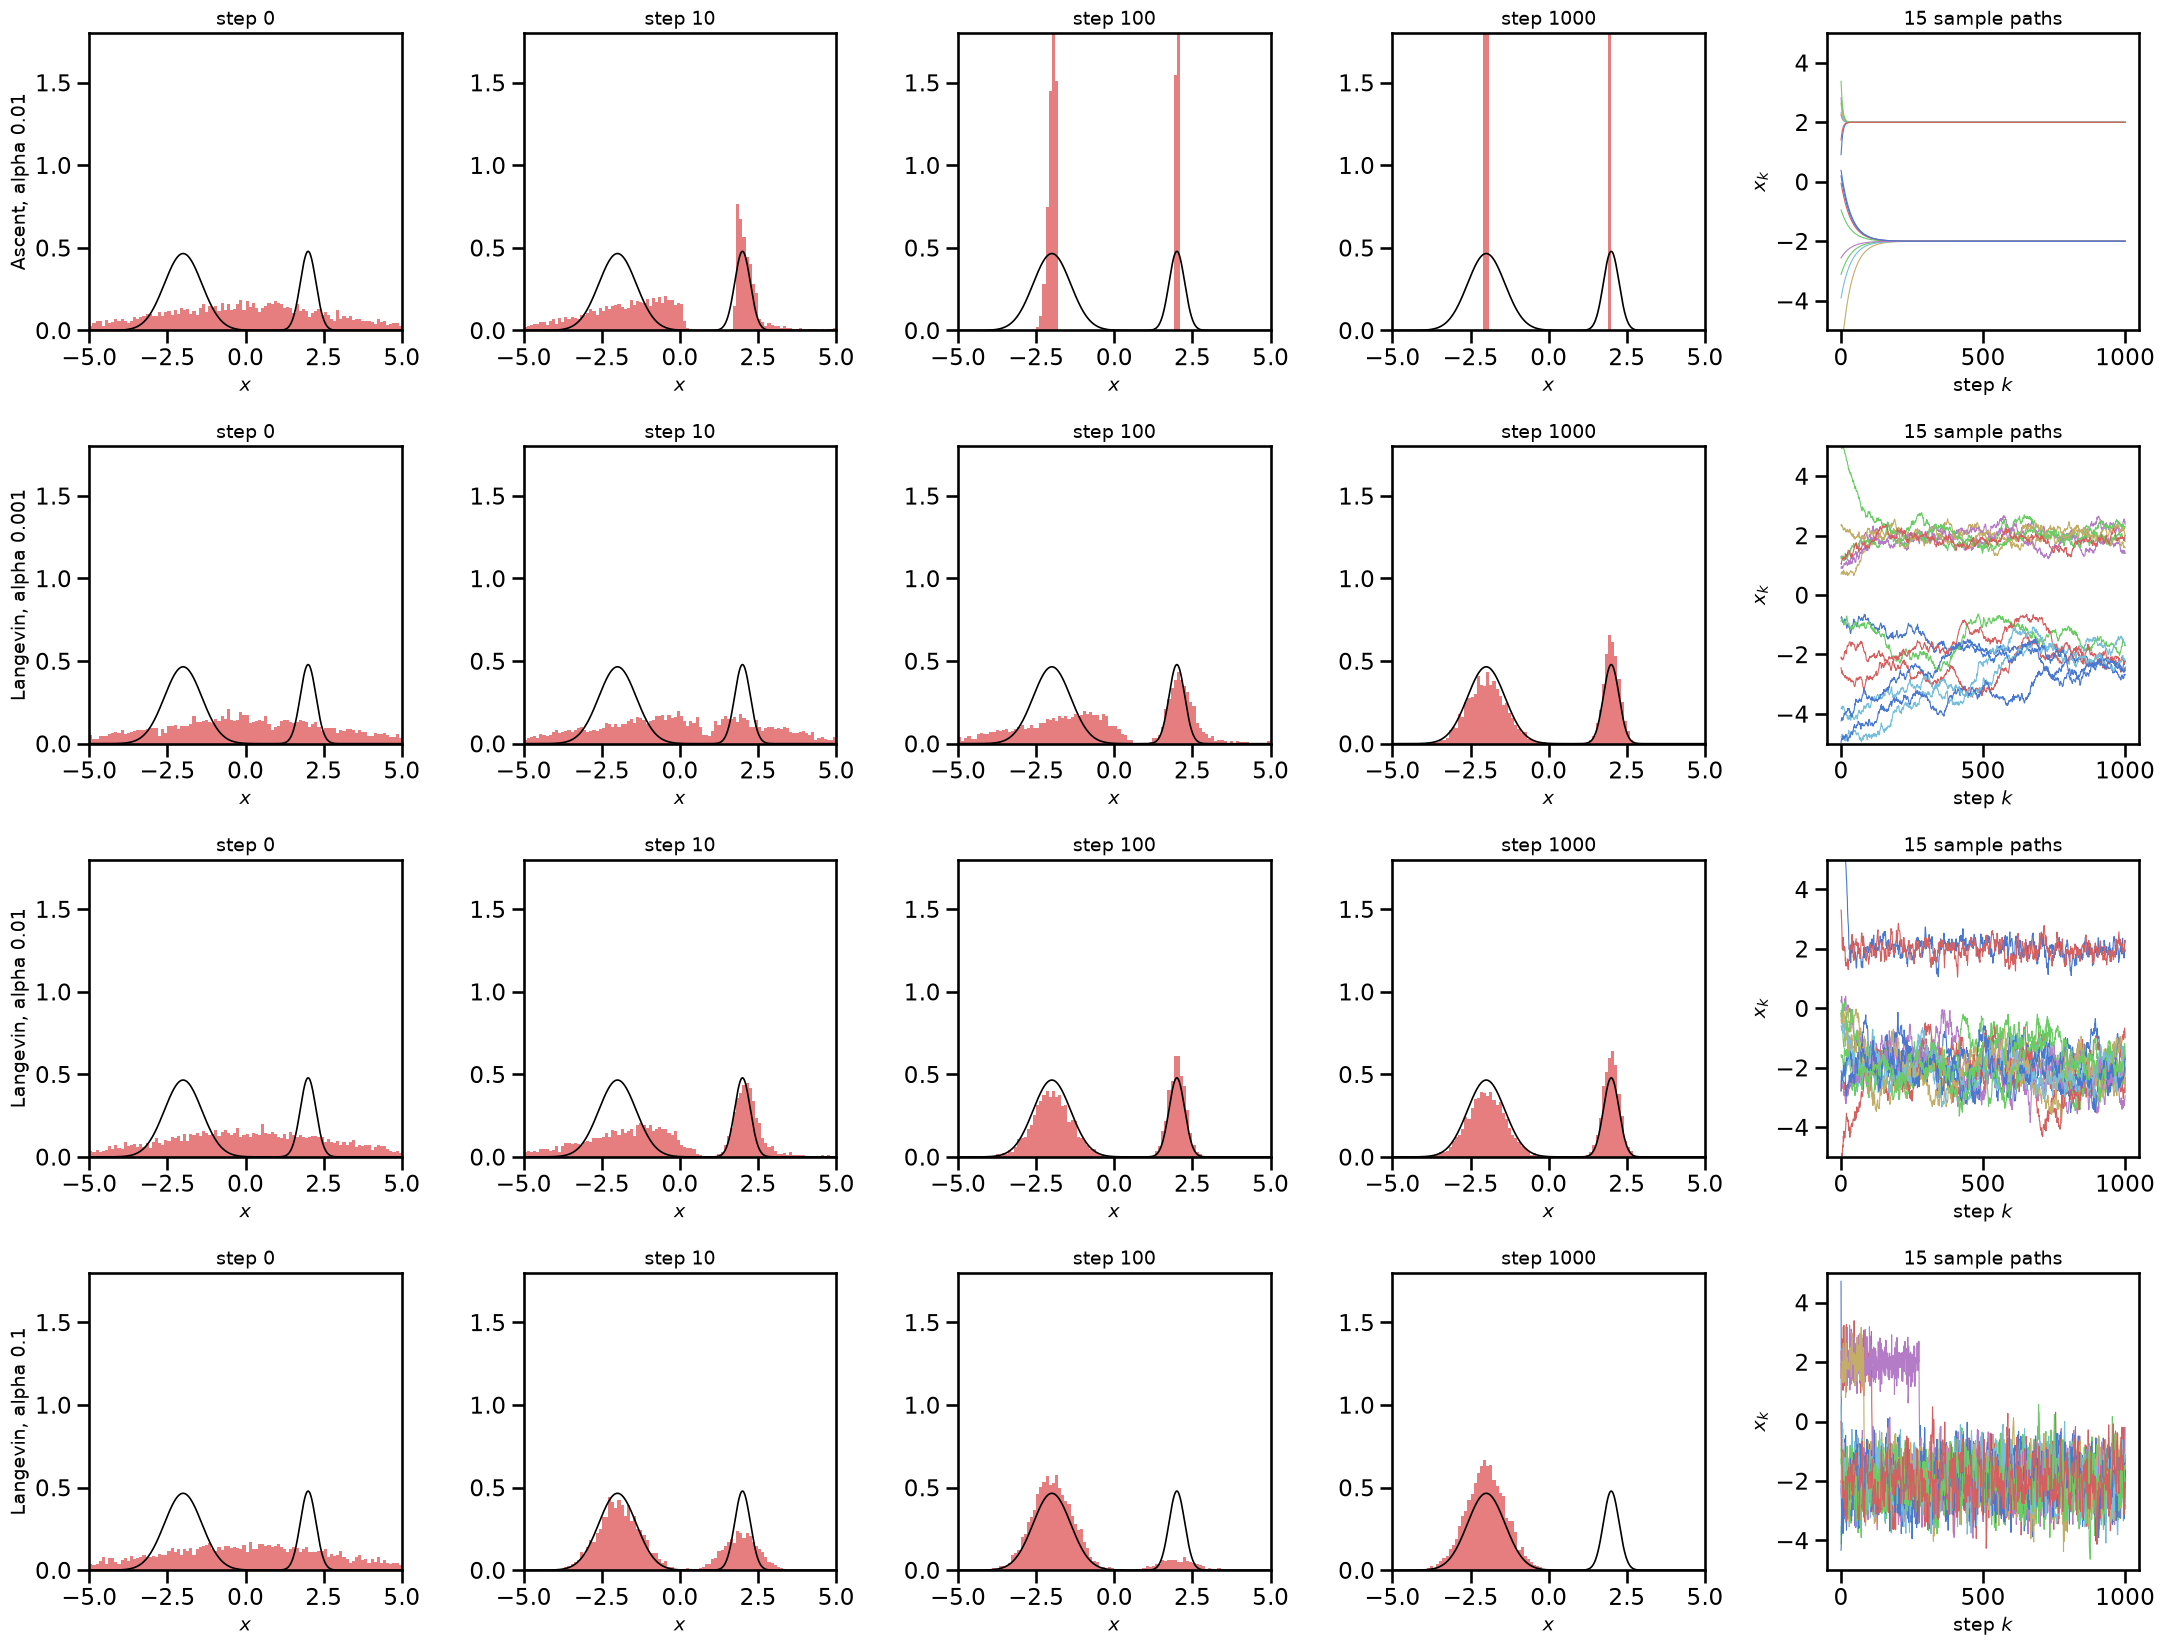

Share of points right of the density minimum at x = 0.79 (target: 0.30)
                             step 0    step 10   step 100  step 1000
Ascent, alpha 0.01             0.39       0.39       0.39       0.39
Langevin, alpha 0.001          0.39       0.39       0.40       0.40
Langevin, alpha 0.01           0.40       0.41       0.41       0.41
Langevin, alpha 0.1            0.40       0.30       0.10       0.00


In [7]:
# Figures for Exercise 3: a 1D two-mode mixture, its exact score, and four samplers step by step
EX_SEED = 42
from math import erf

MIX_W = np.array([0.7, 0.3])
MIX_MU = np.array([-2.0, 2.0])
MIX_SD = np.array([0.6, 0.25])
EX3_N, EX3_STEPS, EX3_SNAPS, EX3_PATHS = 5000, 1000, [0, 10, 100, 1000], 15


def mix_components(x):
    # Weighted component densities, one column per mode
    return MIX_W * np.exp(-0.5 * ((x[:, None] - MIX_MU) / MIX_SD) ** 2) / (MIX_SD * np.sqrt(2 * np.pi))


def mix_pdf(x):
    return mix_components(x).sum(axis=1)


def mix_score(x):
    # d/dx log p(x): each mode's score -(x - mu)/sd^2, weighted by that mode's share of p(x)
    c = mix_components(x)
    resp = c / c.sum(axis=1, keepdims=True)
    return (resp * (-(x[:, None] - MIX_MU) / MIX_SD ** 2)).sum(axis=1)


xs_1d = np.linspace(-5, 5.5, 2101)
x_dip = xs_1d[(xs_1d > -1.5) & (xs_1d < 1.5)][np.argmin(mix_pdf(xs_1d[(xs_1d > -1.5) & (xs_1d < 1.5)]))]  # density minimum between the modes

fig, (ax_p, ax_s) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax_p.plot(xs_1d, mix_pdf(xs_1d), color='k')
ax_p.set_ylabel('$p(x)$')
ax_p.set_title('Target density and its score')
ax_s.plot(xs_1d, mix_score(xs_1d), color='tab:blue')
ax_s.axhline(0, color='0.5', linewidth=0.8)
ax_s.set_ylabel(r'$s(x) = \frac{d}{dx} \log p(x)$')
ax_s.set_xlabel('$x$')
for ax in (ax_p, ax_s):
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

EX3_SETTINGS = [('Ascent, alpha 0.01', 0.01, False), ('Langevin, alpha 0.001', 0.001, True),
                ('Langevin, alpha 0.01', 0.01, True), ('Langevin, alpha 0.1', 0.1, True)]
rng_ex3 = np.random.default_rng(EX_SEED)
ex3_snaps, ex3_paths, ex3_right_share = {}, {}, {}
for name, a, noisy in EX3_SETTINGS:
    x = rng_ex3.normal(0.0, 3.0, EX3_N)
    snaps, paths, share = {0: x.copy()}, [x[:EX3_PATHS].copy()], [np.mean(x > x_dip)]
    for k in range(1, EX3_STEPS + 1):
        x = x + a * mix_score(x)
        if noisy:
            x = x + np.sqrt(2 * a) * rng_ex3.standard_normal(EX3_N)
        paths.append(x[:EX3_PATHS].copy())
        share.append(np.mean(x > x_dip))
        if k in EX3_SNAPS:
            snaps[k] = x.copy()
    ex3_snaps[name], ex3_paths[name], ex3_right_share[name] = snaps, np.array(paths), np.array(share)

fig, axes = plt.subplots(len(EX3_SETTINGS), len(EX3_SNAPS) + 1, figsize=(22, 4.2 * len(EX3_SETTINGS)))
bins_1d = np.linspace(-5, 5, 101)
for r, (name, a, noisy) in enumerate(EX3_SETTINGS):
    for c, k in enumerate(EX3_SNAPS):
        ax = axes[r, c]
        ax.hist(ex3_snaps[name][k], bins=bins_1d, density=True, color='tab:red', alpha=0.6)
        ax.plot(xs_1d, mix_pdf(xs_1d), color='k', linewidth=1.2)
        ax.set_xlim(-5, 5)
        ax.set_ylim(0, 1.8)
        ax.set_title(f'step {k}', fontsize=14)
        ax.set_xlabel('$x$', fontsize=14)
    axes[r, 0].set_ylabel(name, fontsize=14)
    ax = axes[r, -1]
    ax.plot(ex3_paths[name], linewidth=0.8)
    ax.set_ylim(-5, 5)
    ax.set_title(f'{EX3_PATHS} sample paths', fontsize=14)
    ax.set_xlabel('step $k$', fontsize=14)
    ax.set_ylabel('$x_k$', fontsize=14)
plt.tight_layout()
plt.show()

target_right_share = sum(w * 0.5 * (1 - erf((x_dip - m) / (s * np.sqrt(2)))) for w, m, s in zip(MIX_W, MIX_MU, MIX_SD))
print(f'Share of points right of the density minimum at x = {x_dip:.2f} (target: {target_right_share:.2f})')
print(f"{'':24s}" + ''.join(f'{f"step {k}":>11s}' for k in EX3_SNAPS))
for name, a, noisy in EX3_SETTINGS:
    print(f'{name:24s}' + ''.join(f'{ex3_right_share[name][k]:11.2f}' for k in EX3_SNAPS))

In [8]:
# Reading the score
zero = xs_1d[1:][np.sign(mix_score(xs_1d)[1:]) != np.sign(mix_score(xs_1d)[:-1])]
print('Zeros of the score at x =', np.round(zero, 2))
print('Score at x = 0.5: {:.2f}, at x = 1.5: {:.2f}'.format(*mix_score(np.array([0.5, 1.5]))))
print(f'Slope of the score at the left mode {-1 / MIX_SD[0] ** 2:.2f} (= -1/0.6^2), at the right mode {-1 / MIX_SD[1] ** 2:.2f} (= -1/0.25^2)')
right_tail = xs_1d > 3
i_min = np.argmin(mix_score(xs_1d[right_tail]))
print(f'Far right: the score falls to {mix_score(xs_1d[right_tail])[i_min]:.1f} at x = {xs_1d[right_tail][i_min]:.2f}, '
      f'then rises to {mix_score(np.array([5.5]))[0]:.1f} at x = 5.5')
c = mix_components(xs_1d)
print(f'The two weighted components are equal at x = {xs_1d[right_tail][np.argmin(np.abs(np.log(c[right_tail, 0] / c[right_tail, 1])))]:.2f}')

# The split between the modes
x0 = np.random.default_rng(EX_SEED).normal(0.0, 3.0, EX3_N)
print(f'\nShare of the N(0, 3^2) start right of x = {x_dip:.2f}: {np.mean(x0 > x_dip):.2f}')
barrier = np.log(mix_pdf(np.array([2.0]))[0] / mix_pdf(np.array([x_dip]))[0])
print(f'log p(2) - log p({x_dip:.2f}) = {barrier:.1f}, so the density at the dip is {np.exp(-barrier):.1e} times its value at the right peak')
for name, a, noisy in EX3_SETTINGS:
    share = ex3_right_share[name]
    print(f'{name:24s}: share right of the dip at step 100 {share[100]:.3f}, at step 1000 {share[1000]:.3f}, '
          f'smallest after step 100 {share[100:].min():.3f}, largest {share[100:].max():.3f}')
share_01 = ex3_right_share['Langevin, alpha 0.1']
print(f'alpha 0.1: share right of the dip first below 0.05 at step {np.argmax(share_01 < 0.05)}, '
      f'first zero at step {np.argmax(share_01 == 0) if (share_01 == 0).any() else None}')
for name, a in [('Langevin, alpha 0.01', 0.01), ('Langevin, alpha 0.1', 0.1)]:
    right = ex3_snaps[name][100][ex3_snaps[name][100] > x_dip]
    left = ex3_snaps[name][100][ex3_snaps[name][100] < x_dip]
    print(f'{name}, step 100: std of the right mode {right.std():.3f} (target 0.25), of the left mode {left.std():.3f} (target 0.60)')
for s_mode in MIX_SD:
    for a in (0.01, 0.1):
        print(f'Mode with std {s_mode}: alpha {a} gives a sampled std of {s_mode / np.sqrt(1 - a / (2 * s_mode ** 2)):.3f}'
              if a < 2 * s_mode ** 2 else f'Mode with std {s_mode}: alpha {a} is past the limit')

Zeros of the score at x = [-2.    0.79  2.  ]
Score at x = 0.5: -6.94, at x = 1.5: 8.00
Slope of the score at the left mode -2.78 (= -1/0.6^2), at the right mode -16.00 (= -1/0.25^2)
Far right: the score falls to -42.8 at x = 4.72, then rises to -20.8 at x = 5.5
The two weighted components are equal at x = 4.86

Share of the N(0, 3^2) start right of x = 0.79: 0.39
log p(2) - log p(0.79) = 10.5, so the density at the dip is 2.8e-05 times its value at the right peak
Ascent, alpha 0.01      : share right of the dip at step 100 0.392, at step 1000 0.392, smallest after step 100 0.392, largest 0.392
Langevin, alpha 0.001   : share right of the dip at step 100 0.398, at step 1000 0.399, smallest after step 100 0.398, largest 0.399
Langevin, alpha 0.01    : share right of the dip at step 100 0.407, at step 1000 0.406, smallest after step 100 0.406, largest 0.407
Langevin, alpha 0.1     : share right of the dip at step 100 0.095, at step 1000 0.000, smallest after step 100 0.000, largest 0.095

**(a)** The score is zero at $x = -2$, $x = 0.79$ and $x = 2$. The two modes are maxima of $\log p$, and $x = 0.79$ is the minimum of $p$ between them; the slope of $\log p$ is zero at all three. Near a mode, one Gaussian dominates, so $\log p(x) \approx \text{const} - (x - \mu)^2 / (2\,\text{sd}^2)$ and $s(x) \approx -(x - \mu)/\text{sd}^2$. The slope of the score is $-1/\text{sd}^2$: $-2.78$ at the wide mode ($\text{sd} = 0.6$) and $-16.0$ at the narrow mode ($\text{sd} = 0.25$). The weights 0.7 and 0.3, like the normalizing constant, only add a constant to $\log p$ near each mode and so drop out of the score there.

At $x = 0.5$ the score is $-6.94$, so the point moves left, toward the wide mode at $-2$. At $x = 1.5$ it is $+8.00$, so the point moves right, toward the narrow mode at 2. The two points lie on opposite sides of the minimum at 0.79. There the dominant component switches from the wide to the narrow Gaussian, and the score jumps from about $-7$ to about $+16$ over a short distance.

**(b)**

- Deterministic ascent: Each point runs to the maximum on its side of $x = 0.79$ and stops. After 100 steps the histogram is two spikes at $-2$ and 2, and the paths are flat lines. Without noise the update is an optimizer, not a sampler. The share at the right mode stays at 0.39, the share of the starting points that lay right of 0.79.
- Langevin, $\alpha = 0.001$: Correct, but slow. After 10 steps the histogram has barely changed. After 100 steps the narrow mode has formed, while the wide mode is still spread out toward $x = 0$ and below $-4$. The time scale of a mode is about $\text{sd}^2$: 0.0625 (63 steps) for the narrow mode and 0.36 (360 steps) for the wide one, and points that start far out need several of these. After 1000 steps both modes are close to their shapes, and the paths from far out are still drifting in.
- Langevin, $\alpha = 0.01$: After 100 steps both modes have the right shape (standard deviation 0.269 at the right mode and 0.616 at the left, against 0.25 and 0.60) and keep it. The paths fluctuate inside their mode and never cross to the other one.
- Langevin, $\alpha = 0.1$: The step is too large for the narrow mode. It comes out with standard deviation 0.552 at step 100, against 0.25, close to the value $0.25/\sqrt{1 - 0.1/(2 \cdot 0.25^2)} = 0.56$ from Exercise 5. The inflated narrow mode spills over the minimum into the wide mode, which is hardly affected (0.65 predicted against 0.60). The share at the right mode falls from 0.40 to 0.30 at step 10, 0.10 at step 100 and 0.00 at step 1000; it drops below 5% at step 146. In the path plot, the paths that started on the right jump to the left one after another. They do not come back, because the wide mode's spread rarely reaches past the minimum.

**(c)** The 41% comes from the start. About 39% of $\mathcal{N}(0, 3^2)$ lies right of $x = 0.79$, and in the first steps every point runs down the score to the mode on its side of the minimum. Near each mode the score only describes that mode's shape, as in (a). The 70/30 weights do not appear in it, so the points in each mode stay there and keep the share they started with. The share stays between 0.406 and 0.407 from step 100 to step 1000.

To change the split, points have to cross the minimum between the modes, in proportions that move the shares toward 70/30. At the minimum, $p$ is $2.8 \times 10^{-5}$ times its value at the right peak, so a crossing needs the noise to push a point up a long way against the score, and that almost never happens. The weights enter the dynamics only through how often points cross in each direction. Running longer would fix the split in principle, because $p$ is the stationary distribution of Langevin dynamics (up to the step-size error from Exercise 2). As a rough estimate, the waiting time for one point to cross grows like the inverse of that density ratio, which puts it at the order of $10^5$ steps or more at $\alpha = 0.01$, against the 1000 steps run here. Another fixed $\alpha$ does not help either. A smaller step only slows everything down. A larger step distorts the narrow mode instead of mixing: $\alpha = 0.1$ moves the split, but to 0/100 rather than 30/70.

**(d)** A large $\sigma$ blurs $p$ with $\mathcal{N}(0, \sigma^2)$. Once $\sigma$ is comparable with the distance between the modes, the deep minimum between them fills in, and the score between the modes becomes small and smooth instead of switching sharply from one mode to the other. Points then cross easily in both directions. The blurring does not change the weights: $p_\sigma$ is still a mixture of the same two components, each widened, with weights 0.7 and 0.3. Combined, this means Langevin dynamics on $p_\sigma$ mixes quickly and puts 70% of the points on the left and 30% on the right. If $\sigma$ is then lowered in steps, with a few Langevin steps at each level, each point settles into the mode it is already near, and the modes keep the shares they received while crossing was still easy. This is annealed Langevin dynamics. Diffusion models, in the next chapter, learn the score at every noise level for exactly this purpose.

**(e)** In the tails, the narrow Gaussian decays like $\exp(-(x - 2)^2/(2 \cdot 0.25^2))$ and the wide one like $\exp(-(x + 2)^2/(2 \cdot 0.6^2))$. The narrow one falls off much faster, so beyond $x \approx 4.86$ the wide Gaussian dominates again, although it is centered at $-2$. The score switches from the narrow mode's $-(x - 2)/0.0625$ (it reaches $-42.8$ at $x = 4.72$) to the wide mode's $-(x + 2)/0.36$ ($-20.8$ at $x = 5.5$). Hardly any points ever get there, so the jump does not affect sampling.

### Exercise 4: What went wrong with the sampler that worked on the ring?

In [9]:
EX_SEED = 42  # seed for the exercise runs


class ValleyScore(nn.Module):
    """Exact score of a narrow Gaussian valley: std 2 along it, 0.06 across it, rotated by -30 degrees."""

    def __init__(self, std_along=2.0, std_across=0.06, angle_deg=-30.0):
        super().__init__()
        angle = np.deg2rad(angle_deg)
        self.along = torch.tensor([np.cos(angle), np.sin(angle)], dtype=torch.float32)    # unit vector along the valley
        self.across = torch.tensor([-np.sin(angle), np.cos(angle)], dtype=torch.float32)  # unit vector across it
        self.std_along, self.std_across = std_along, std_across

    def forward(self, x):
        u = x @ self.along   # coordinate along the valley
        v = x @ self.across  # coordinate across the valley
        return -(u / self.std_along ** 2)[:, None] * self.along - (v / self.std_across ** 2)[:, None] * self.across


valley_score = ValleyScore()

# Run 1: the chapter's call, unchanged (alpha = 0.01, 200 steps, start from N(0, 5^2 I))
torch.manual_seed(EX_SEED)
valley_run1, _ = langevin_sampler_2d(valley_score, n_samples=1000, alpha=0.01)

# Run 2: a smaller step size
torch.manual_seed(EX_SEED)
valley_run2, _ = langevin_sampler_2d(valley_score, n_samples=1000, n_steps=500, alpha=0.007)

# Runs 3 and 4: a much smaller step size, for 500 and for 5000 steps
torch.manual_seed(EX_SEED)
valley_run3, _ = langevin_sampler_2d(valley_score, n_samples=1000, n_steps=500, alpha=0.001)
torch.manual_seed(EX_SEED)
valley_run4, _ = langevin_sampler_2d(valley_score, n_samples=1000, n_steps=5000, alpha=0.001)

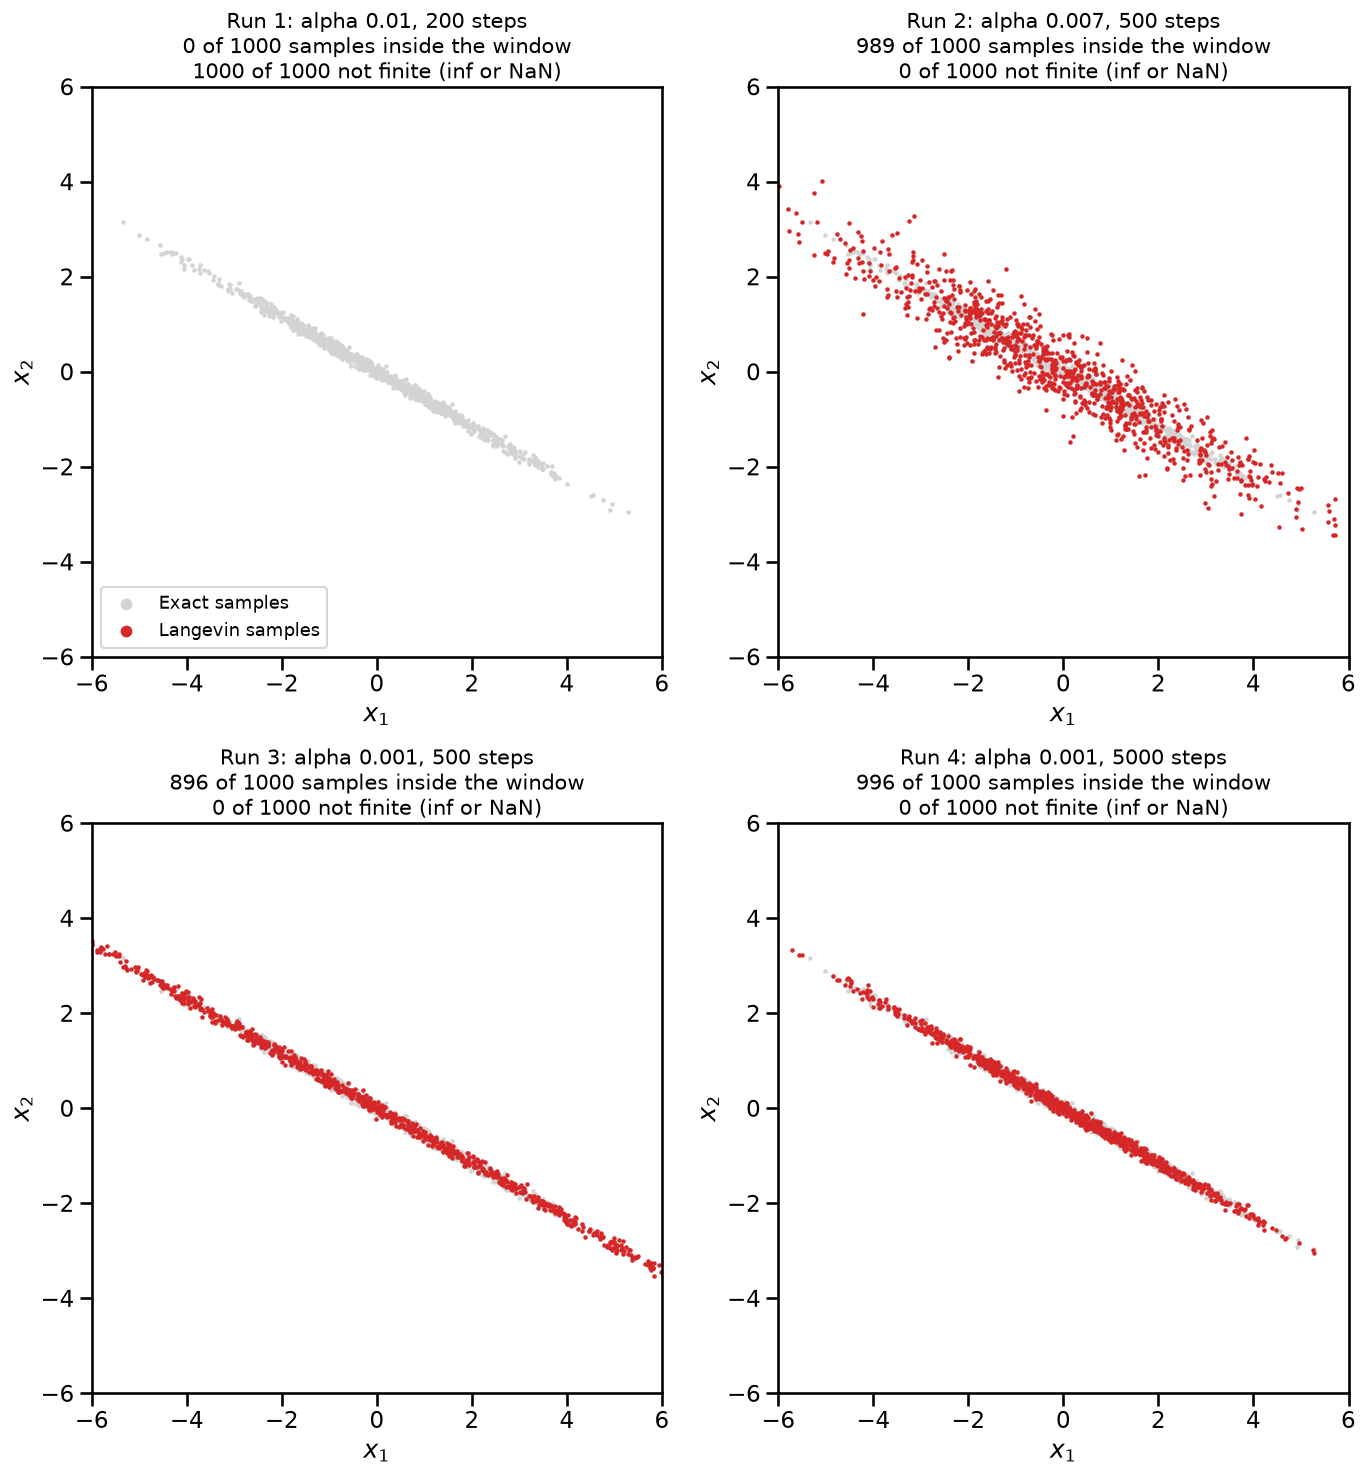

In [10]:
# Figure for Exercise 4: the four runs over exact samples of the valley
torch.manual_seed(EX_SEED)
valley_exact = (2.0 * torch.randn(1000, 1) * valley_score.along + 0.06 * torch.randn(1000, 1) * valley_score.across).numpy()
valley_runs = {'Run 1: alpha 0.01, 200 steps': valley_run1, 'Run 2: alpha 0.007, 500 steps': valley_run2,
               'Run 3: alpha 0.001, 500 steps': valley_run3, 'Run 4: alpha 0.001, 5000 steps': valley_run4}
VALLEY_LIM = 6.0
fig, axes = plt.subplots(2, 2, figsize=(14, 15))
for ax, (title, x) in zip(axes.ravel(), valley_runs.items()):
    x = x.cpu().numpy()
    finite = np.isfinite(x).all(axis=1)
    inside = finite & (np.abs(x) < VALLEY_LIM).all(axis=1)
    ax.scatter(valley_exact[:, 0], valley_exact[:, 1], s=3, color='lightgray', label='Exact samples')
    ax.scatter(x[inside, 0], x[inside, 1], s=3, color='tab:red', label='Langevin samples')
    ax.set_title(f'{title}\n{inside.sum()} of {len(x)} samples inside the window\n'
                 f'{(~finite).sum()} of {len(x)} not finite (inf or NaN)', fontsize=15)
    ax.set_xlim(-VALLEY_LIM, VALLEY_LIM)
    ax.set_ylim(-VALLEY_LIM, VALLEY_LIM)
    ax.set_aspect('equal')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
axes[0, 0].legend(loc='lower left', fontsize=13, markerscale=4)
plt.tight_layout()
plt.show()

In [11]:
# What happened in each run, measured along (u) and across (v) the valley
torch.manual_seed(EX_SEED)
_, traj1 = langevin_sampler_2d(valley_score, n_samples=1000, alpha=0.01)  # run 1 again, keeping the trajectory
v1 = traj1 @ valley_score.across.numpy()
for k in [0, 1, 10, 50, 100, 140]:
    print(f'Run 1, step {k:3d}: largest |v| across the valley {np.nanmax(np.abs(v1[k])):.3g}')
first_bad = np.argmax(~np.isfinite(traj1).all(axis=(1, 2)))
print(f'Run 1: first step with a non-finite sample {first_bad}; finite samples at the end {np.isfinite(traj1[-1]).all(axis=1).sum()}')
print(f'Growth factor per step across the valley at alpha 0.01: |1 - alpha / 0.06^2| = {abs(1 - 0.01 / 0.06 ** 2):.2f}; '
      f'along it: {abs(1 - 0.01 / 2.0 ** 2):.4f}')
print(f'Step size limit 2 * 0.06^2 = {2 * 0.06 ** 2:.4f}\n')
print(f"{'run':>4} {'alpha':>6} {'steps':>6} {'std along (target 2.00)':>24} {'std across (target 0.060)':>26} {'predicted across':>17}")
for i, (run, a, steps) in enumerate([(valley_run2, 0.007, 500), (valley_run3, 0.001, 500), (valley_run4, 0.001, 5000)], start=2):
    x = run.cpu().numpy()
    u, v = x @ valley_score.along.numpy(), x @ valley_score.across.numpy()
    print(f'{i:>4} {a:6.3f} {steps:6d} {u.std():24.2f} {v.std():26.3f} {0.06 / np.sqrt(1 - a / (2 * 0.06 ** 2)):17.3f}')
for i, run in enumerate([valley_run1, valley_run2, valley_run3, valley_run4], start=1):
    x = run.cpu().numpy()
    inside = np.isfinite(x).all(axis=1) & (np.abs(x) < VALLEY_LIM).all(axis=1)
    print(f'Run {i}: {inside.sum()} of {len(x)} samples inside the window')
for steps in [500, 5000, 20000]:
    t = 0.001 * steps
    print(f'alpha 0.001, {steps} steps: predicted std along from a N(0, 5^2) start {np.sqrt(4 + (25 - 4) * np.exp(-2 * t / 4)):.2f}')

Run 1, step   0: largest |v| across the valley 16.2
Run 1, step   1: largest |v| across the valley 28.7
Run 1, step  10: largest |v| across the valley 5.12e+03
Run 1, step  50: largest |v| across the valley 5.06e+13
Run 1, step 100: largest |v| across the valley 1.58e+26
Run 1, step 140: largest |v| across the valley 1.56e+36
Run 1: first step with a non-finite sample 141; finite samples at the end 0
Growth factor per step across the valley at alpha 0.01: |1 - alpha / 0.06^2| = 1.78; along it: 0.9975
Step size limit 2 * 0.06^2 = 0.0072

 run  alpha  steps  std along (target 2.00)  std across (target 0.060)  predicted across
   2  0.007    500                     2.67                      0.357             0.360
   3  0.001    500                     4.30                      0.063             0.065
   4  0.001   5000                     2.36                      0.063             0.065
Run 1: 0 of 1000 samples inside the window
Run 2: 989 of 1000 samples inside the window
Run 3: 896 of

**(a)** Run 1 diverged. Its panel shows no red points, and its title says why: all 1000 samples are infinite or not a number after 200 steps (the first non-finite value appears at step 141). Across the valley the score is $-v/0.06^2$, so each step multiplies $v$ by $1 - 0.01/0.06^2 = -1.78$. The step overshoots to the other side of the valley and lands farther out each time. The largest $|v|$ grows from 16 at the start to about $5 \times 10^3$ after 10 steps and $1.6 \times 10^{36}$ after 140 steps, and then overflows. The noise has nothing to do with it. The step size has to be small compared with the narrowest length scale of the target: the stable range is $\alpha < 2 \cdot 0.06^2 = 0.0072$ (Exercise 5). On the ring, the narrowest scale was the cluster standard deviation 0.25, blurred to $\sqrt{0.25^2 + 0.1^2} = 0.27$ by the training noise, which allows $\alpha$ up to 0.145. That is why $\alpha = 0.01$ worked there.

**(b)** Run 2 is stable, but the valley is about six times too wide across: the samples have standard deviation 0.357 across it, against 0.06. The step size 0.007 is just below the limit 0.0072. Each step multiplies $v$ by $-0.94$, so $v$ changes sign at every step and shrinks only slowly, while the noise adds variance $2\alpha$ at every step. The two balance at a variance of $0.06^2 / (1 - 0.007/(2 \cdot 0.06^2)) = 0.36^2$ (Exercise 5). Near the limit this error grows without bound. Reducing the step size by 30% takes the factor from $-1.78$ (growth) to $-0.94$ (slow decay), which is why the two runs look so different.

**(c)** Run 3 has the right width across (0.063, against 0.06 for the target and 0.065 predicted for this $\alpha$), but the samples reach far beyond the ends of the valley: their standard deviation along it is 4.30 instead of 2.00, and 104 of the 1000 samples are outside the window. Along the valley the score is only $-u/2^2$, so each step shrinks $u$ by a factor of $1 - 0.001/4 = 0.99975$. The spread along the valley relaxes on a time scale of about $2^2 = 4$, which is 4000 steps at this $\alpha$. After 500 steps the starting spread of 5 has only come down to 4.30 (4.51 predicted from the drift alone). After 5000 steps it is 2.36 (2.39 predicted), and it takes about 20 000 steps to reach 2.00.

**(d)** A step size safely below the limit, for example $\alpha = 0.001$ (width across 8% too large), and about 20 000 steps, which is 100 times the chapter's 200 steps. The narrow direction sets the largest stable step, and the wide direction sets how far the samples have to travel. The number of steps grows like the ratio of the two variances, $(2/0.06)^2 \approx 1100$. On the ring, the clusters were round and every length scale was similar, so a few hundred steps were enough.

### Exercise 5: Why the valley diverges (optional take-home)

In [12]:
s_v = 0.06
for a in [0.001, 0.005, 0.007, 0.0072, 0.01]:
    factor = 1 - a / s_v ** 2
    var = s_v ** 2 / (1 - a / (2 * s_v ** 2)) if abs(factor) < 1 else np.inf
    print(f'alpha {a:.4f}: factor 1 - alpha/s^2 = {factor:+.3f}, stationary std across {np.sqrt(var):.3f} (target {s_v})')

alpha 0.0010: factor 1 - alpha/s^2 = +0.722, stationary std across 0.065 (target 0.06)
alpha 0.0050: factor 1 - alpha/s^2 = -0.389, stationary std across 0.109 (target 0.06)
alpha 0.0070: factor 1 - alpha/s^2 = -0.944, stationary std across 0.360 (target 0.06)
alpha 0.0072: factor 1 - alpha/s^2 = -1.000, stationary std across inf (target 0.06)
alpha 0.0100: factor 1 - alpha/s^2 = -1.778, stationary std across inf (target 0.06)


**(a)** $|v|$ grows when $|1 - \alpha/s^2| > 1$, that is, when $\alpha > 2s^2 = 0.0072$. For $s^2 < \alpha < 2s^2$ each step overshoots the center, but by less than the previous offset, so $v$ oscillates and shrinks. The noise does not rescue the sampler, because it is added independently of $v$: the noiseless part, $(1 - \alpha/s^2)^k v_0$, still grows geometrically, and the noise only adds to it. Run 1 ($\alpha = 0.01$, factor $-1.78$) is above the limit and diverged; run 2 ($\alpha = 0.007$, factor $-0.94$) is just below it and stayed finite.

**(b)** The stationary variance is $s^2 / (1 - \alpha/(2s^2))$. It tends to $s^2$ as $\alpha \to 0$ and grows without bound as $\alpha \to 2s^2$. For $\alpha = 0.007$ it is $0.0036/(1 - 0.972) = 0.130$, a standard deviation of 0.360. That matches the 0.357 measured across the valley in run 2.

::: {.callout-note collapse="true"}
### Derivation of the stationary variance
Write $a = \alpha/s^2$. A stationary variance $V$ satisfies $V = (1 - a)^2 V + 2\alpha$, so

$$
V = \frac{2\alpha}{1 - (1 - a)^2} = \frac{2\alpha}{a(2 - a)} = \frac{2 s^2}{2 - a} = \frac{s^2}{1 - \alpha/(2s^2)}.
$$

The iteration converges to $V$ only if $(1 - a)^2 < 1$, which is the same condition $\alpha < 2s^2$ as in (a).
:::

**(c)** It is the stability limit of explicit time integration. A spring with stiffness $k$ and a damper $c$, with no mass, follows $c\,\dot{x} = -k x$. Explicit Euler gives $x_{n+1} = (1 - h k/c)\, x_n$, which is stable only for $h < 2c/k$. In an explicit transient simulation, the stiffest element in the model sets the critical time step in the same way. Langevin's drift is explicit Euler on $\dot{x} = s(x)$, and a Gaussian direction with variance $s^2$ acts like a spring with stiffness $1/s^2$: $1/0.06^2 = 278$ across the valley and $1/2^2 = 0.25$ along it, a ratio of about 1100. The stiff direction limits the step, and the soft direction sets how long the system takes to settle. So the number of steps grows with the stiffness ratio, exactly as for a structure that combines a very stiff and a very soft spring.